# Emotion Classification from Text
**Dataset:** `train.txt` — 16,000 labeled sentences across 6 emotions  
**Model:** TF-IDF + Logistic Regression (with fixes for class imbalance & stable label mapping)


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import joblib
import warnings
warnings.filterwarnings('ignore')

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt',     quiet=True)
nltk.download('wordnet',   quiet=True)

from nltk.corpus   import stopwords
from nltk.stem     import WordNetLemmatizer

from sklearn.model_selection        import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model           import LogisticRegression
from sklearn.naive_bayes            import MultinomialNB
from sklearn.svm                    import LinearSVC
from sklearn.pipeline               import Pipeline
from sklearn.metrics                import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

print("All imports successful ✓")


All imports successful ✓


## 2. Load Dataset

In [2]:
# train.txt format:  text;emotion  (no header)
df = pd.read_csv('train.txt', sep=';', header=None, names=['text', 'emotion'])

print(f"Shape: {df.shape}")
print(f"Null values:\n{df.isnull().sum()}")
df.head(8)


Shape: (16000, 2)
Null values:
text       0
emotion    0
dtype: int64


,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
5,ive been feeling a little burdened lately wasn...,sadness
6,ive been taking or milligrams or times recomme...,surprise
7,i feel as confused about life as a teenager or...,fear


Emotion → ID mapping: {'sadness': 0, 'joy': 1, 'love': 2, 'anger': 3, 'fear': 4, 'surprise': 5}

Class distribution:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


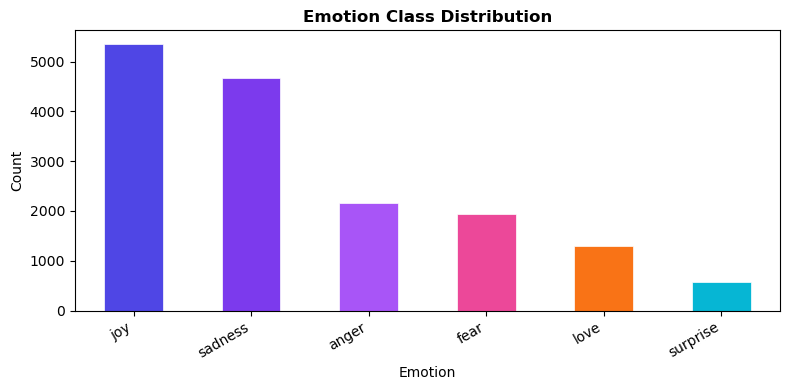

NOTE: Dataset is imbalanced — 'joy' has 9× more samples than 'surprise'
      → This is why models trained without class_weight always predict the majority class!


In [15]:
# ── FIX 1: Use a FIXED, STABLE label mapping (not random unique()) ──
EMOTION_MAP = {
    'sadness':  0,
    'joy':      1,
    'love':     2,
    'anger':    3,
    'fear':     4,
    'surprise': 5,
}
ID_TO_EMOTION = {v: k for k, v in EMOTION_MAP.items()}

df['label'] = df['emotion'].map(EMOTION_MAP)

print("Emotion → ID mapping:", EMOTION_MAP)
print()
print("Class distribution:")
dist = df['emotion'].value_counts()
print(dist)

# Visualise imbalance
plt.figure(figsize=(8, 4))
colors = ['#4f46e5','#7c3aed','#a855f7','#ec4899','#f97316','#06b6d4']
dist.plot(kind='bar', color=colors, edgecolor='white', linewidth=0.5)
plt.title('Emotion Class Distribution', fontweight='bold')
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()
print("NOTE: Dataset is imbalanced — 'joy' has 9× more samples than 'surprise'")
print("      → This is why models trained without class_weight always predict the majority class!")


## 3. Text Preprocessing

In [16]:
lemmatizer  = WordNetLemmatizer()
stop_words  = set(stopwords.words('english'))

# Keep negation words — they flip sentiment!
KEEP = {'no', 'not', "n't", 'nor', 'never', 'nobody', 'nothing',
        'neither', 'nowhere', 'hardly', 'barely', 'scarcely'}
stop_words -= KEEP

def preprocess(text):
    if not isinstance(text, str):
        return ""
    # Lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # Remove emojis / non-ascii
    text = text.encode('ascii', 'ignore').decode()
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Remove digits
    text = re.sub(r'\d+', '', text)
    # Tokenise, remove stopwords, lemmatise
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return ' '.join(tokens)

df['text_clean'] = df['text'].apply(preprocess)

print("Before:", df.loc[1, 'text'])
print("After: ", df.loc[1, 'text_clean'])
df[['text', 'text_clean', 'emotion']].head(6)


Before: i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
After:  go feeling hopeless damned hopeful around someone care awake


,text,text_clean,emotion
0,i didnt feel humiliated,didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,go feeling hopeless damned hopeful around some...,sadness
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,ever feeling nostalgic fireplace know still pr...,love
4,i am feeling grouchy,feeling grouchy,anger
5,ive been feeling a little burdened lately wasn...,ive feeling little burdened lately wasnt sure,sadness


## 4. Train / Test Split

In [17]:
X = df['text_clean'].values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y          # keeps class ratio the same in both splits
)

print(f"Train samples : {len(X_train):,}")
print(f"Test  samples : {len(X_test):,}")

# Confirm stratification held
train_dist = pd.Series(y_train).value_counts().sort_index()
test_dist  = pd.Series(y_test ).value_counts().sort_index()
check = pd.DataFrame({
    'Train': train_dist.values,
    'Test' : test_dist.values
}, index=[ID_TO_EMOTION[i] for i in train_dist.index])
print()
print(check)


Train samples : 12,800
Test  samples : 3,200

          Train  Test
sadness    3733   933
joy        4290  1072
love       1043   261
anger      1727   432
fear       1550   387
surprise    457   115


## 5. TF-IDF Vectorizer

In [18]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),   # unigrams + bigrams (catches 'not happy', 'feel angry')
    max_features=30000,
    min_df=2,             # ignore words appearing in only 1 document
    max_df=0.95,          # ignore words in >95% of documents
    sublinear_tf=True,    # log(tf) — reduces dominance of very frequent words
    strip_accents='unicode',
)

X_train_vec = tfidf.fit_transform(X_train)
X_test_vec  = tfidf.transform(X_test)

print(f"Vocabulary size : {len(tfidf.vocabulary_):,} features")
print(f"Train matrix    : {X_train_vec.shape}")
print(f"Test  matrix    : {X_test_vec.shape}")


Vocabulary size : 14,308 features
Train matrix    : (12800, 14308)
Test  matrix    : (3200, 14308)


## 6. Train & Compare Models

In [19]:
# ── FIX 2: class_weight='balanced' — compensates for the imbalanced dataset ──
models = {
    'Logistic Regression': LogisticRegression(
        C=5.0,
        class_weight='balanced',   # KEY FIX
        max_iter=1000,
        solver='lbfgs',
        multi_class='multinomial',
        random_state=42,
    ),
    'Naive Bayes (TF-IDF)': MultinomialNB(alpha=0.3),
    'Linear SVM': LinearSVC(
        C=1.0,
        class_weight='balanced',   # KEY FIX
        max_iter=2000,
        random_state=42,
    ),
}

results = {}
for name, model in models.items():
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)
    acc = accuracy_score(y_test, preds)
    results[name] = {'model': model, 'preds': preds, 'accuracy': acc}
    print(f"{name:30s}  Accuracy = {acc:.4f}")

best_name = max(results, key=lambda k: results[k]['accuracy'])
print(f"\nBest model: {best_name} ({results[best_name]['accuracy']:.4f})")


Logistic Regression             Accuracy = 0.9025
Naive Bayes (TF-IDF)            Accuracy = 0.7984
Linear SVM                      Accuracy = 0.9094

Best model: Linear SVM (0.9094)


## 7. Detailed Evaluation — Best Model

In [20]:
best_model = results[best_name]['model']
best_preds = results[best_name]['preds']

emotion_names = [ID_TO_EMOTION[i] for i in sorted(ID_TO_EMOTION)]

print("=" * 55)
print(f"Model: {best_name}")
print("=" * 55)
print(classification_report(y_test, best_preds, target_names=emotion_names))


Model: Linear SVM
              precision    recall  f1-score   support

     sadness       0.96      0.93      0.95       933
         joy       0.94      0.91      0.92      1072
        love       0.77      0.87      0.82       261
       anger       0.90      0.91      0.91       432
        fear       0.87      0.89      0.88       387
    surprise       0.79      0.83      0.81       115

    accuracy                           0.91      3200
   macro avg       0.87      0.89      0.88      3200
weighted avg       0.91      0.91      0.91      3200



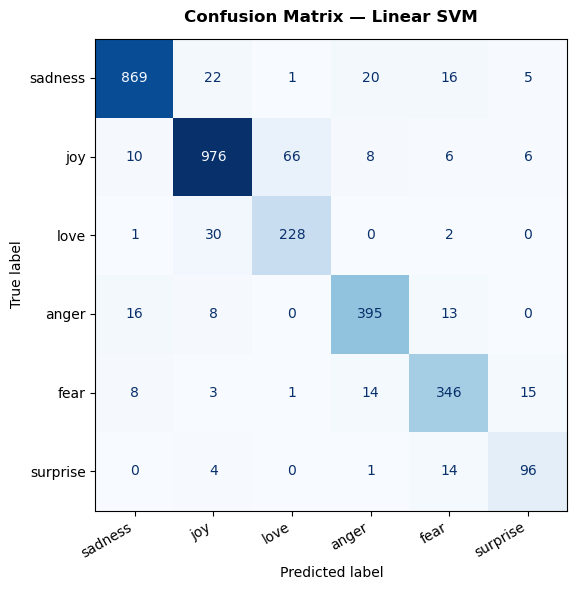

In [21]:
# Confusion matrix
cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=emotion_names)
disp.plot(cmap='Blues', colorbar=False, ax=plt.gca())
plt.title(f'Confusion Matrix — {best_name}', fontweight='bold', pad=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()


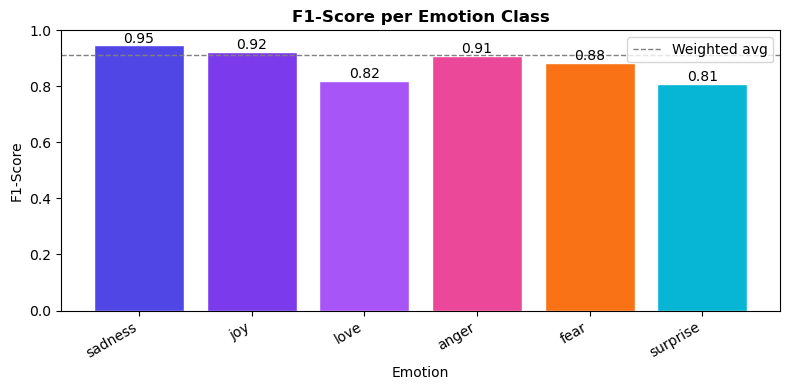

In [22]:
# Per-class accuracy bar chart
report = classification_report(y_test, best_preds, target_names=emotion_names, output_dict=True)
f1_scores = {k: report[k]['f1-score'] for k in emotion_names}

plt.figure(figsize=(8, 4))
bars = plt.bar(f1_scores.keys(), f1_scores.values(), color=colors, edgecolor='white')
plt.axhline(y=report['weighted avg']['f1-score'], color='gray',
            linestyle='--', linewidth=1, label='Weighted avg')
plt.ylim(0, 1)
plt.title('F1-Score per Emotion Class', fontweight='bold')
plt.xlabel('Emotion')
plt.ylabel('F1-Score')
plt.legend()
plt.xticks(rotation=30, ha='right')
for bar, val in zip(bars, f1_scores.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.2f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('f1_per_class.png', dpi=150)
plt.show()


## 8. Top Predictive Words per Emotion

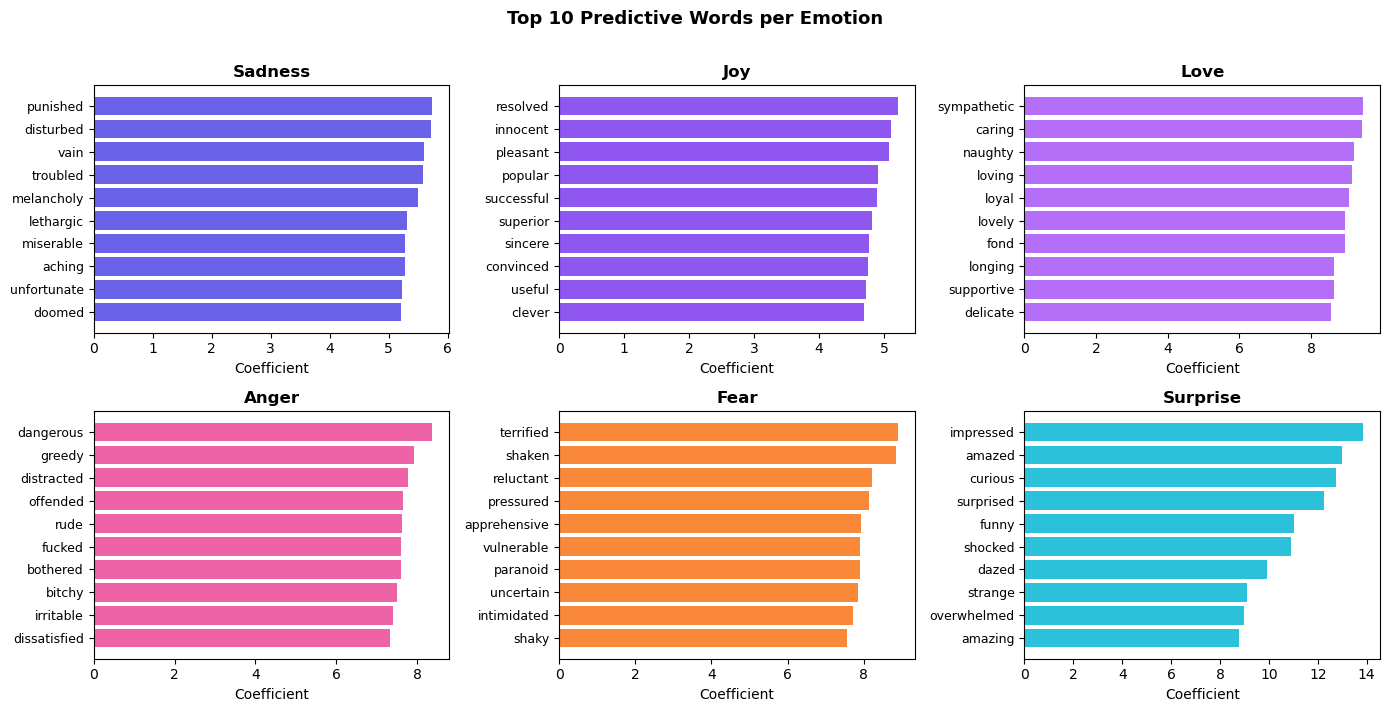

In [23]:
# Only works for Logistic Regression (has .coef_)
lr_model = results['Logistic Regression']['model']
feature_names = tfidf.get_feature_names_out()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for idx, emotion in enumerate(emotion_names):
    coefs = lr_model.coef_[idx]
    top_n = 10
    top_idx   = coefs.argsort()[-top_n:][::-1]
    top_words = [feature_names[i] for i in top_idx]
    top_vals  = [coefs[i] for i in top_idx]

    axes[idx].barh(top_words[::-1], top_vals[::-1], color=colors[idx], alpha=0.85)
    axes[idx].set_title(f'{emotion.capitalize()}', fontweight='bold')
    axes[idx].tick_params(axis='y', labelsize=9)
    axes[idx].set_xlabel('Coefficient')

plt.suptitle('Top 10 Predictive Words per Emotion', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('top_features.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Save Model & Vectorizer

In [24]:
joblib.dump(best_model, 'sentiment_model.pkl')
joblib.dump(tfidf,      'tfidf_vectorizer.pkl')
joblib.dump(EMOTION_MAP,'emotion_map.pkl')

print("Saved:")
print("  sentiment_model.pkl    — trained classifier")
print("  tfidf_vectorizer.pkl   — fitted TF-IDF vectorizer")
print("  emotion_map.pkl        — emotion ↔ id mapping")


Saved:
  sentiment_model.pkl    — trained classifier
  tfidf_vectorizer.pkl   — fitted TF-IDF vectorizer
  emotion_map.pkl        — emotion ↔ id mapping


## 10. Run Inference on New Text

In [25]:
# Load saved model
loaded_model     = joblib.load('sentiment_model.pkl')
loaded_vectorizer= joblib.load('tfidf_vectorizer.pkl')
loaded_map       = joblib.load('emotion_map.pkl')
id_to_emo        = {v: k for k, v in loaded_map.items()}

def predict_emotion(text):
    cleaned = preprocess(text)
    vec     = loaded_vectorizer.transform([cleaned])
    pred_id = loaded_model.predict(vec)[0]
    emotion = id_to_emo[pred_id]

    # Probability scores (not available for LinearSVC)
    try:
        proba   = loaded_model.predict_proba(vec)[0]
        scores  = {id_to_emo[i]: round(float(p), 3) for i, p in enumerate(proba)}
        scores  = dict(sorted(scores.items(), key=lambda x: -x[1]))
    except AttributeError:
        scores = {emotion: 1.0}

    print(f"Text     : {text}")
    print(f"Emotion  : {emotion.upper()}")
    print(f"Scores   : {scores}")
    print()
    return emotion, scores

# ── Test cases ──
predict_emotion("I am so happy today, everything feels wonderful!")
predict_emotion("I am devastated, this is the worst day of my life.")
predict_emotion("I can't believe this happened, I'm in shock!")
predict_emotion("I feel so lonely and hopeless right now.")
predict_emotion("I love spending time with my family.")
predict_emotion("This makes me really angry, it's unfair!")


Text     : I am so happy today, everything feels wonderful!
Emotion  : JOY
Scores   : {'joy': 1.0}

Text     : I am devastated, this is the worst day of my life.
Emotion  : SADNESS
Scores   : {'sadness': 1.0}

Text     : I can't believe this happened, I'm in shock!
Emotion  : ANGER
Scores   : {'anger': 1.0}

Text     : I feel so lonely and hopeless right now.
Emotion  : SADNESS
Scores   : {'sadness': 1.0}

Text     : I love spending time with my family.
Emotion  : JOY
Scores   : {'joy': 1.0}

Text     : This makes me really angry, it's unfair!
Emotion  : ANGER
Scores   : {'anger': 1.0}



('anger', {'anger': 1.0})